# Atividade 1 - Primeiro contato com PyTorch — Cat vs. Not Cat

## Objetivo
Construir uma rede neural simples para classificar imagens como gato ou não-gato.

O código não está pronto. Em cada etapa, você deverá desenvolver sua solução.

**Fluxo:** dados → rede neural → treinamento → resultado → uma alteração → comparação

### Dataset

O dataset desta atividade é o arquivo **`cat_not_cat.csv`**. Esse arquivo não possui cabeçalho. Cada linha representa uma imagem. As primeiras colunas contêm os valores dos pixels, e a última coluna contém o label da imagem.

O arquivo deve ficar na mesma pasta do notebook; caso contrário, ajuste o caminho no código.

> O objetivo desta atividade também é desenvolver sua autonomia na busca por conhecimento. Se você não souber como fazer algo, seja utilizar o GitHub, implementar uma etapa ou entender um conceito, pesquise e busque compreender antes de seguir. Faz parte da atividade aprender a encontrar as respostas.

> Você não precisa entender ainda toda a matemática do treinamento. Neste momento, o objetivo é aprender a usar o PyTorch e reconhecer as principais etapas.

## 0. Prepare sua branch no repositório

Antes de iniciar a atividade, acesse o repositório do projeto e crie uma branch própria para desenvolver e salvar seu exercício.

Repositório: https://github.com/LCCMat-UnB/segmentacao-laminas

Cada aluno deverá trabalhar em uma branch separada, sem alterar diretamente a branch main.

Use um nome que identifique claramente sua branch, por exemplo:

`atividade-1-seunome`

Não adicione o arquivo `cat_not_cat.csv` à sua branch. Faça o commit apenas do notebook e dos arquivos produzidos pela atividade.

Durante o desenvolvimento da atividade:

1. salve o notebook da atividade na sua branch;
2. faça commits ao longo do trabalho;
3. mantenha suas alterações apenas na sua branch;
4. ao finalizar a atividade, faça o último commit com a versão completa do notebook.

## 1. Conheça o dataset

### Respostas

1. **Existem 259 exemplos** no dataset (cada linha do CSV corresponde a uma imagem).
2. **`X` representa as entradas:** a matriz de pixels com formato `(259, 12288)` — uma linha por imagem, uma coluna por pixel.
3. **`y` representa os rótulos:** vetor de inteiros `{0, 1}` indicando "não-gato" (0) e "gato" (1).
4. As duas classes são **0 = não-gato** e **1 = gato**.
5. Cada imagem é representada como um vetor de **12 288 valores** (= 64 × 64 pixels × 3 canais RGB).
   Reorganizando para `(64, 64, 3)` obtemos a imagem original.


In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Semente global para reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

csv_path = Path("cat_not_cat.csv")
df = pd.read_csv(csv_path, header=None)

X = df.iloc[:, :-1].to_numpy(dtype=np.float32)
y = df.iloc[:, -1].to_numpy(dtype=np.int64)

classes, counts = np.unique(y, return_counts=True)

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)
print("Valores únicos em y:", np.unique(y))
print("Primeiros 10 valores de X[0]:", X[0, :10])
print("Classes e quantidades:", dict(zip(classes.tolist(), counts.tolist())))
print("Menor pixel:", float(X.min()), "| Maior pixel:", float(X.max()))


Formato de X: (259, 12288)
Formato de y: (259,)
Valores únicos em y: [0 1]
Primeiros 10 valores de X[0]: [17. 31. 56. 22. 33. 59. 25. 35. 62. 25.]
Classes e quantidades: {0: 154, 1: 105}
Menor pixel: 0.0 | Maior pixel: 255.0


Label da imagem 0: 0


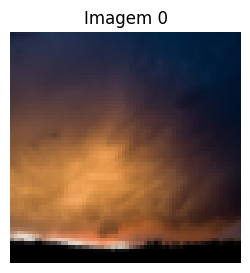

In [2]:
# Visualização: primeira imagem
print("Label da imagem 0:", y[0])
img0 = X[0].reshape(64, 64, 3).astype("uint8")
plt.figure(figsize=(3, 3))
plt.imshow(img0)
plt.title("Imagem 0")
plt.axis("off")
plt.show()


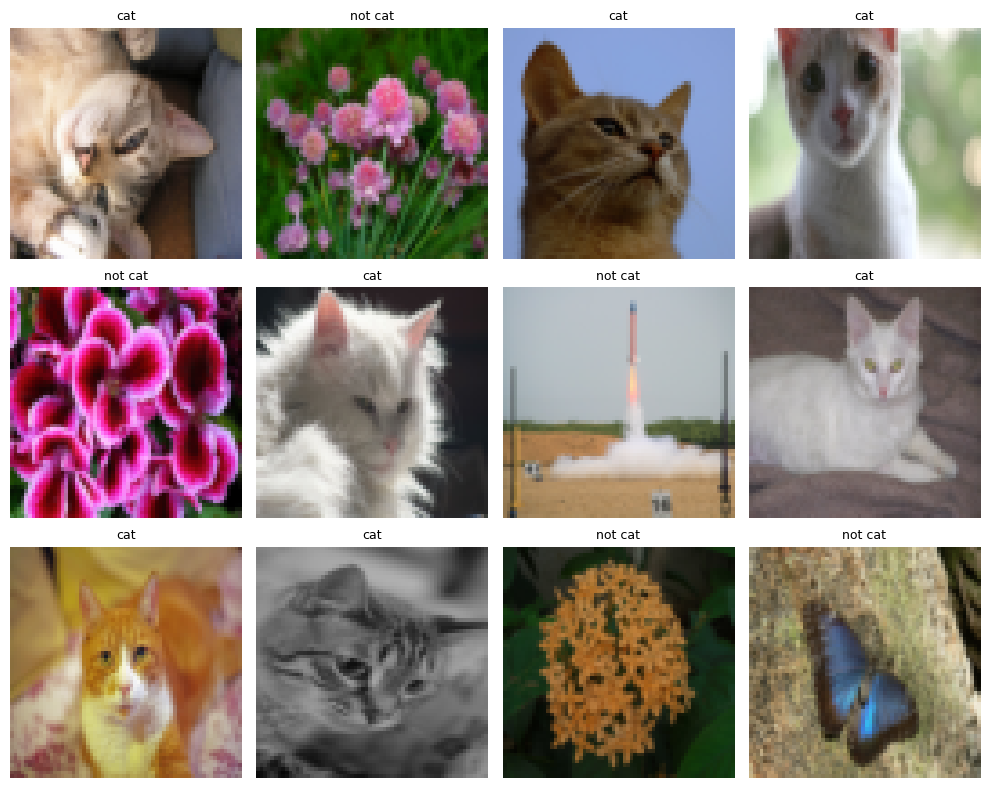

In [3]:
# Mostra 12 imagens aleatórias do dataset
n_images = 12
indices = np.random.default_rng(SEED).choice(len(X), size=n_images, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax, i in zip(axes.ravel(), indices):
    img = X[i].reshape(64, 64, 3).astype("uint8")
    label = "cat" if y[i] == 1 else "not cat"
    ax.imshow(img)
    ax.set_title(label, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


## 2. Separe os dados em treino e teste

### Respostas

1. Escolhi **80 % treino / 20 % teste**. Com apenas 259 exemplos é importante
   deixar a maior parte para o modelo aprender; 20 % ainda reserva ~52 imagens
   nunca vistas durante o treinamento.
2. A separação serve para estimar a **capacidade de generalização** do modelo:
   o conjunto de treino ajusta os pesos, o conjunto de teste mede o desempenho
   em dados novos.
3. Avaliar somente no treino pode enganar — o modelo pode ter decorado os
   exemplos (*overfitting*) e apresentar alta acurácia sem realmente generalizar.

`stratify=y` mantém a proporção das classes nos dois conjuntos;
`random_state=42` torna a divisão reproduzível.


In [4]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split

torch.manual_seed(SEED)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=SEED,
    stratify=y,
)

def contar_classes(rotulos):
    cls, cnt = np.unique(rotulos, return_counts=True)
    return dict(zip(cls.tolist(), cnt.tolist()))

print("Treino:", X_train_raw.shape, "— classes:", contar_classes(y_train))
print("Teste: ", X_test_raw.shape,  "— classes:", contar_classes(y_test))


Treino: (207, 12288) — classes: {0: 123, 1: 84}
Teste:  (52, 12288) — classes: {0: 31, 1: 21}


## 3. Prepare os dados

### Respostas

1. Os pixels têm valores de **0 a 255**.
2. Sim, é necessário normalizar. Valores muito grandes podem causar atualizações
   instáveis nos pesos e dificultar a convergência do otimizador.
3. Dividi cada valor por **255**, levando os pixels ao intervalo `[0, 1]`.
   Convertemos `X` para `float32` (tipo esperado pelo PyTorch) e `y` para
   `float32` com formato `[n, 1]` (compatível com `BCEWithLogitsLoss`).
4. A normalização min-max preserva a escala relativa dos pixels e é simples
   de implementar; o intervalo `[0, 1]` é convencional para dados de imagem.
5. Um **tensor** é uma estrutura de dados multidimensional, generalização de
   vetores e matrizes. No PyTorch os tensores também armazenam informações para
   o cálculo automático de gradientes (autograd).

> Observação: `X_train_raw` e `X_test_raw` são mantidos sem divisão,
  evitando aplicar a normalização duas vezes caso a célula seja re-executada.


In [5]:
# Normalização: divide por 255 → intervalo [0, 1]
X_train_t = torch.tensor(X_train_raw / 255.0, dtype=torch.float32)
X_test_t  = torch.tensor(X_test_raw  / 255.0, dtype=torch.float32)

# Labels em float32, formato [n, 1] exigido pelo BCEWithLogitsLoss
y_train_t = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_test_t  = torch.tensor(y_test,  dtype=torch.float32).reshape(-1, 1)

print("X_train:", X_train_t.shape, X_train_t.dtype)
print("X_test: ", X_test_t.shape,  X_test_t.dtype)
print("y_train:", y_train_t.shape, y_train_t.dtype)
print("Intervalo normalizado:", float(X_train_t.min()), "a", float(X_train_t.max()))


X_train: torch.Size([207, 12288]) torch.float32
X_test:  torch.Size([52, 12288]) torch.float32
y_train: torch.Size([207, 1]) torch.float32
Intervalo normalizado: 0.0 a 1.0


## 4. Organize os dados para o treinamento

### Respostas

1. O **DataLoader** é um iterador que agrupa automaticamente os exemplos em
   lotes (*batches*), embaralha os dados a cada época e oferece uma interface
   uniforme independente do tamanho do dataset.
2. Um **batch** é um subconjunto de exemplos processados juntos antes de
   uma atualização dos pesos.
3. **batch_size = 32** significa que a cada passo de gradiente a rede processa
   32 imagens. Com 207 exemplos de treino isso resulta em 6 lotes completos
   de 32 e um último lote com 15.
4. Embaralhar os dados evita que a rede aprenda a ordem de chegada dos
   exemplos, tornando as atualizações de pesos mais variadas e o treinamento
   mais robusto.


In [6]:
BATCH_SIZE = 32

dataset_treino = TensorDataset(X_train_t, y_train_t)

def criar_loader(dataset, batch_size=BATCH_SIZE, shuffle=True):
    gerador = torch.Generator().manual_seed(SEED)
    return DataLoader(dataset, batch_size=batch_size,
                      shuffle=shuffle, generator=gerador)

loader_treino = criar_loader(dataset_treino)

# Inspeciona o primeiro batch
X_batch, y_batch = next(iter(loader_treino))
print("Número de imagens de treino:", len(dataset_treino))
print("Número de batches:          ", len(loader_treino))
print("Primeiro batch — X:", X_batch.shape, "| y:", y_batch.shape)


Número de imagens de treino: 207
Número de batches:           7
Primeiro batch — X: torch.Size([32, 12288]) | y: torch.Size([32, 1])


## 5. Crie a rede neural

### Respostas

1. Entram **12 288 valores** por exemplo (64 × 64 × 3 pixels achatados).
2. A camada intermediária possui **16 neurônios**.
3. A função de ativação é a **ReLU** (`max(0, x)`).
4. A rede possui **uma única saída** (logit), adequada para classificação binária.
5. A ReLU introduz **não-linearidade** sem o problema de saturação do gradiente
   que afeta a sigmoid nas regiões extremas. É simples, computacionalmente barata
   e frequentemente propicia convergência mais rápida.
   A sigmoid é omitida aqui pois `BCEWithLogitsLoss` já a combina
   internamente com a entropia cruzada binária, de forma numericamente estável.


In [7]:
torch.manual_seed(SEED)

modelo_baseline = nn.Sequential(
    nn.Linear(12_288, 16),   # camada oculta: 12 288 → 16
    nn.ReLU(),               # ativação não-linear
    nn.Linear(16, 1),        # saída: 16 → 1 logit
)

print(modelo_baseline)
n_params = sum(p.numel() for p in modelo_baseline.parameters())
print(f"Total de parâmetros: {n_params:,}")


Sequential(
  (0): Linear(in_features=12288, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)
Total de parâmetros: 196,641


## 6. Configure o treinamento

### Respostas

1. A **loss** (função de perda) mede o quão erradas são as previsões do modelo.
   Ela guia o ajuste dos pesos: o otimizador tenta minimizá-la.
2. `BCEWithLogitsLoss` é adequada porque o problema tem **duas classes** e
   **uma saída em logit**. A função combina sigmoid e binary cross-entropy
   com melhor estabilidade numérica do que aplicá-las em separado.
3. O **optimizer** usa os gradientes calculados pelo *backpropagation* para
   atualizar os pesos e vieses da rede na direção que reduz a loss.
4. O **learning rate** (taxa de aprendizado) controla o tamanho de cada
   atualização. Um valor alto pode ultrapassar bons mínimos; um valor baixo
   pode tornar o aprendizado muito lento.
5. Uma **epoch** é uma passagem completa por todos os exemplos de treino.
   Com 10 epochs, a rede vê cada exemplo de treino 10 vezes.


In [8]:
criterio = nn.BCEWithLogitsLoss()
LR     = 0.001
EPOCHS = 10

otimizador_baseline = torch.optim.Adam(modelo_baseline.parameters(), lr=LR)

print("Função de loss:", criterio)
print("Learning rate: ", LR)
print("Epochs:        ", EPOCHS)


Função de loss: BCEWithLogitsLoss()
Learning rate:  0.001
Epochs:         10


## 7. Treine o baseline

### O que acontece em cada batch

1. `zero_grad()` — limpa os gradientes acumulados do passo anterior.
2. **Forward pass** — o modelo calcula os logits.
3. **Loss** — a função de perda compara logits com os rótulos reais.
4. `backward()` — calcula os gradientes por retropropagação.
5. `step()` — o otimizador atualiza os pesos usando os gradientes.

### Respostas (preenchidas após o treinamento)

As perguntas 1-3 são respondidas com base nos valores impressos abaixo.


In [9]:
def treinar(modelo, loader, otimizador, n_epochs=EPOCHS):
    """Treina o modelo e retorna o histórico de loss por epoch."""
    historico = []
    for epoch in range(n_epochs):
        modelo.train()
        perda_acum = 0.0
        for X_b, y_b in loader:
            otimizador.zero_grad()
            logits = modelo(X_b)
            perda  = criterio(logits, y_b)
            perda.backward()
            otimizador.step()
            perda_acum += perda.item() * X_b.size(0)

        loss_media = perda_acum / len(loader.dataset)
        historico.append(loss_media)
        print(f"Época {epoch + 1:02d}: loss = {loss_media:.4f}")
    return historico

# Recria o loader para que a inspeção acima não altere a ordem
loader_treino = criar_loader(dataset_treino)

historico_baseline = treinar(modelo_baseline, loader_treino, otimizador_baseline)


Época 01: loss = 0.9311
Época 02: loss = 0.6532
Época 03: loss = 0.6237


Época 04: loss = 0.6115
Época 05: loss = 0.5996
Época 06: loss = 0.5913
Época 07: loss = 0.5812


Época 08: loss = 0.5659
Época 09: loss = 0.6083
Época 10: loss = 0.5799


## 8. Veja o resultado

### Respostas

1. O gráfico mostra a **queda geral da loss** ao longo das 10 epochs, com uma pequena alta na época 9 (oscilação normal em treinamento por minibatches). A tendência geral é de redução.
2. A accuracy do baseline foi **59,62%** (31 acertos em 52 imagens de teste).
3. Uma accuracy de 80 % significaria que o modelo classifica corretamente 8 de cada 10 imagens. Porém, accuracy isolada pode enganar — veja a observação abaixo.

### Registre
**Accuracy do baseline:** 59,62%  
**Loss final do baseline:** 0,5799  

> **Leitura crítica:** o conjunto de teste tem exatamente 31 imagens "não-gato" em 52 (≈ 59,6 %). A matriz de confusão mostra VN=31, VP=0 — o modelo classificou **todas** as imagens como "não-gato". Portanto, a accuracy do baseline coincide com a proporção da classe majoritária: um classificador ingênuo faria o mesmo. A loss caiu, mas o modelo ainda não produz uma solução útil para detectar gatos.


Accuracy do baseline:  59.62%
Matriz de confusão:    {'VN': 31, 'FP': 0, 'FN': 21, 'VP': 0}


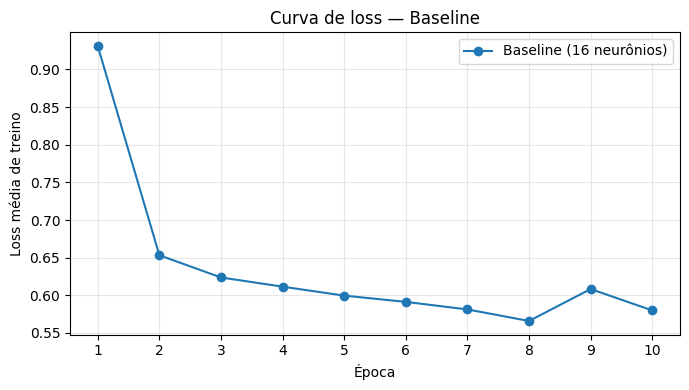

In [10]:
def avaliar(modelo, X_t, y_t):
    """Retorna (accuracy, matriz_confusão) para o conjunto dado."""
    modelo.eval()
    with torch.no_grad():
        prob  = torch.sigmoid(modelo(X_t))
        pred  = (prob >= 0.5).float()

    acc  = (pred == y_t).float().mean().item()
    conf = {
        "VN": int(((pred == 0) & (y_t == 0)).sum()),
        "FP": int(((pred == 1) & (y_t == 0)).sum()),
        "FN": int(((pred == 0) & (y_t == 1)).sum()),
        "VP": int(((pred == 1) & (y_t == 1)).sum()),
    }
    return acc, conf

acc_b, conf_b = avaliar(modelo_baseline, X_test_t, y_test_t)
print(f"Accuracy do baseline:  {acc_b * 100:.2f}%")
print("Matriz de confusão:   ", conf_b)

# Gráfico da loss
epocas = range(1, EPOCHS + 1)
plt.figure(figsize=(7, 4))
plt.plot(epocas, historico_baseline, marker='o', label='Baseline (16 neurônios)')
plt.xlabel("Época")
plt.ylabel("Loss média de treino")
plt.title("Curva de loss — Baseline")
plt.xticks(list(epocas))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 9. Faça uma alteração

### Antes do teste

1. Vou alterar a **quantidade de neurônios da camada oculta de 16 para 64**.
2. Uma camada maior tem maior **capacidade de representação** — pode capturar
   combinações mais complexas de pixels. Quero verificar se 16 neurônios
   limitava a expressividade do modelo.
3. Hipótese: a loss de treino vai **diminuir** (mais capacidade). A accuracy
   de teste pode melhorar se o modelo capturar padrões mais gerais, mas também
   pode piorar se começar a memorizar o conjunto pequeno (*overfitting*).

Todos os demais hiperparâmetros (divisão dos dados, normalização, batch size,
embaralhamento, learning rate, otimizador, loss, epochs, limiar 0.5) permanecem
iguais ao baseline.


In [11]:
torch.manual_seed(SEED)

modelo_exp = nn.Sequential(
    nn.Linear(12_288, 64),   # única alteração: 16 → 64 neurônios
    nn.ReLU(),
    nn.Linear(64, 1),
)

otimizador_exp = torch.optim.Adam(modelo_exp.parameters(), lr=LR)
loader_exp     = criar_loader(dataset_treino)   # recria para ter a mesma ordem

print("Modelo do experimento:")
print(modelo_exp)
print()

historico_exp = treinar(modelo_exp, loader_exp, otimizador_exp)

acc_e, conf_e = avaliar(modelo_exp, X_test_t, y_test_t)
print()
print(f"Accuracy do experimento: {acc_e * 100:.2f}%")
print("Matriz de confusão:      ", conf_e)


Modelo do experimento:
Sequential(
  (0): Linear(in_features=12288, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=1, bias=True)
)

Época 01: loss = 0.9623


Época 02: loss = 0.8854
Época 03: loss = 0.6919


Época 04: loss = 0.6102
Época 05: loss = 0.5546


Época 06: loss = 0.5421
Época 07: loss = 0.5187


Época 08: loss = 0.4880
Época 09: loss = 0.5157


Época 10: loss = 0.4892

Accuracy do experimento: 53.85%
Matriz de confusão:       {'VN': 12, 'FP': 19, 'FN': 5, 'VP': 16}


## 10. Compare

| Métrica | Baseline | Meu experimento |
|---|---:|---:|
| Camada oculta | 16 neurônios | 64 neurônios |
| Accuracy de teste | 59,62% | 53,85% |
| Loss final de treino | 0,5799 | 0,4892 |
| Verdadeiros Positivos (VP) | 0 | 16 |
| Falsos Positivos (FP) | 0 | 19 |

### Respostas

1. Mudei somente o **tamanho da camada oculta** (de 16 para 64 neurônios).
2. A accuracy **diminuiu** 5,77 pontos percentuais (de 59,62 % para 53,85 %).
3. A loss final de treino **diminuiu** de 0,5799 para 0,4892.
4. O modelo maior ajustou melhor os dados de treino (loss menor), mas generalizou pior em termos de accuracy total. Isso é compatível com **overfitting**: o dataset é muito pequeno para suportar uma camada de 64 neurônios sem regularização. Contudo, a matriz de confusão traz uma nuance importante: o baseline nunca detectou um único gato (VP = 0), enquanto o experimento reconheceu 16 dos 21 gatos — ao custo de 19 falsos alarmes. Portanto, avaliar somente pela accuracy pode levar a conclusões erradas.


Métrica                          Baseline  Experimento
Camada oculta                  16 neurônios 64 neurônios
Accuracy de teste (%)              59.62%       53.85%
Loss final de treino               0.5799       0.4892
Verdadeiros Positivos                   0           16
Falsos Positivos                        0           19


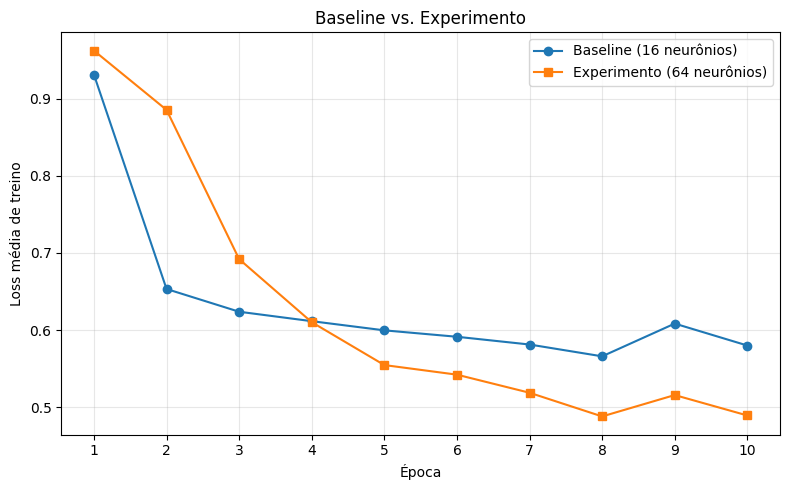

In [12]:
print("=" * 50)
print(f"{'Métrica':<30} {'Baseline':>10} {'Experimento':>12}")
print("=" * 50)
print(f"{'Camada oculta':<30} {'16 neurônios':>10} {'64 neurônios':>12}")
print(f"{'Accuracy de teste (%)':<30} {acc_b*100:>9.2f}% {acc_e*100:>11.2f}%")
print(f"{'Loss final de treino':<30} {historico_baseline[-1]:>10.4f} {historico_exp[-1]:>12.4f}")
print(f"{'Verdadeiros Positivos':<30} {conf_b['VP']:>10} {conf_e['VP']:>12}")
print(f"{'Falsos Positivos':<30} {conf_b['FP']:>10} {conf_e['FP']:>12}")
print("=" * 50)

# Gráfico comparativo das curvas de loss
epocas = range(1, EPOCHS + 1)
plt.figure(figsize=(8, 5))
plt.plot(epocas, historico_baseline, marker='o', label='Baseline (16 neurônios)')
plt.plot(epocas, historico_exp,      marker='s', label='Experimento (64 neurônios)')
plt.xlabel("Época")
plt.ylabel("Loss média de treino")
plt.title("Baseline vs. Experimento")
plt.xticks(list(epocas))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
